<h1 style="font-family:verdana;"> <center>Exercise Clustering   





Customer segmentation with K-Means, DBSCAN and agglomerative clustering</center> </h1>



>Shop analysis in a shopping centre is about understanding customer behaviour in order to strategically optimise business development. The basis should be customer segmentation, in which customers are categorised on the basis of fundamental information in order to adapt marketing and improve the shopping experience.


<h2 style="color:blue">Exercise 1: Exploratory data analysis</h2>



Use the data set `Shop_Customers.csv` 

* **Familiarise yourself with the structure and quality of the data**

* **Use visualisations to capture the complexity of the data set**. If you need to know more about visualization, use chatgpt or google to do so



By gaining insights into the behaviour and characteristics of the shopping centre's customers, we prepare ourselves for the application of **clustering techniques**. This allows us to better categorise and understand the customer base.


In [1]:
# --- Exercise 1: Exploratory Data Analysis -------------------------------
# (imports repeated here so the notebook runs top-to-bottom; the full import
#  block of the course template follows further down)
import os
os.environ["OMP_NUM_THREADS"] = "1"   # silence the MKL/KMeans memory-leak warning on Windows

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("./data/Shop_Customers.csv")
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:
# Structure of the data set
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [3]:
# --- Data quality check --------------------------------------------------
print("Missing values per column:")
print(df.isnull().sum(), "\n")

print("Duplicated rows      :", df.duplicated().sum())
print("Duplicated CustomerID:", df["CustomerID"].duplicated().sum(), "\n")

print("Gender distribution:")
print(df["Gender"].value_counts(), "\n")

df.describe()

Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64 

Duplicated rows      : 0
Duplicated CustomerID: 0 

Gender distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64 



,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [4]:
# Shorter column names make the plots and the code much more readable
df = df.rename(columns={"Annual Income (k$)": "Income",
                        "Spending Score (1-100)": "Score"})

# CustomerID is only a running number -> no information for clustering
features = ["Age", "Income", "Score"]
df[features].agg(["min", "max", "mean", "std"]).round(2)

,Age,Income,Score
min,18.00,15.00,1.00
max,70.00,137.00,99.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82


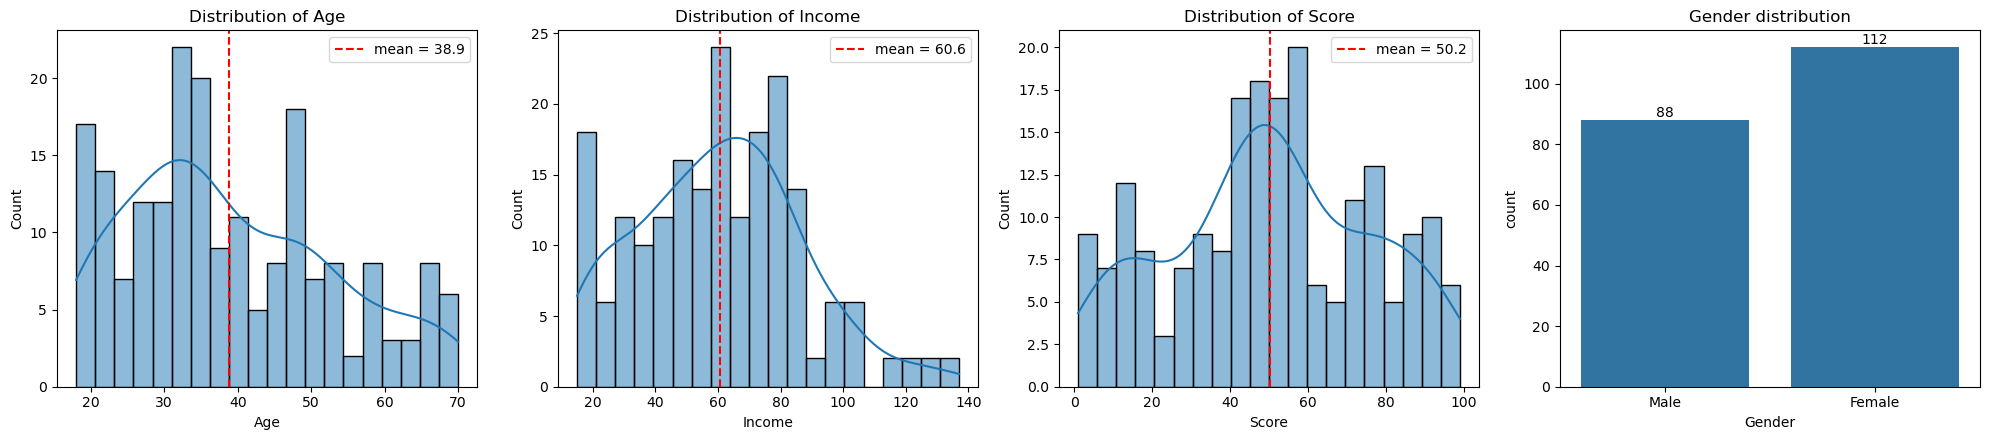

In [5]:
# --- Univariate distributions -------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for ax, col in zip(axes[:3], features):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"mean = {df[col].mean():.1f}")
    ax.set_title(f"Distribution of {col}")
    ax.legend()

sns.countplot(data=df, x="Gender", ax=axes[3])
axes[3].set_title("Gender distribution")
for container in axes[3].containers:
    axes[3].bar_label(container)

plt.tight_layout()
plt.show()

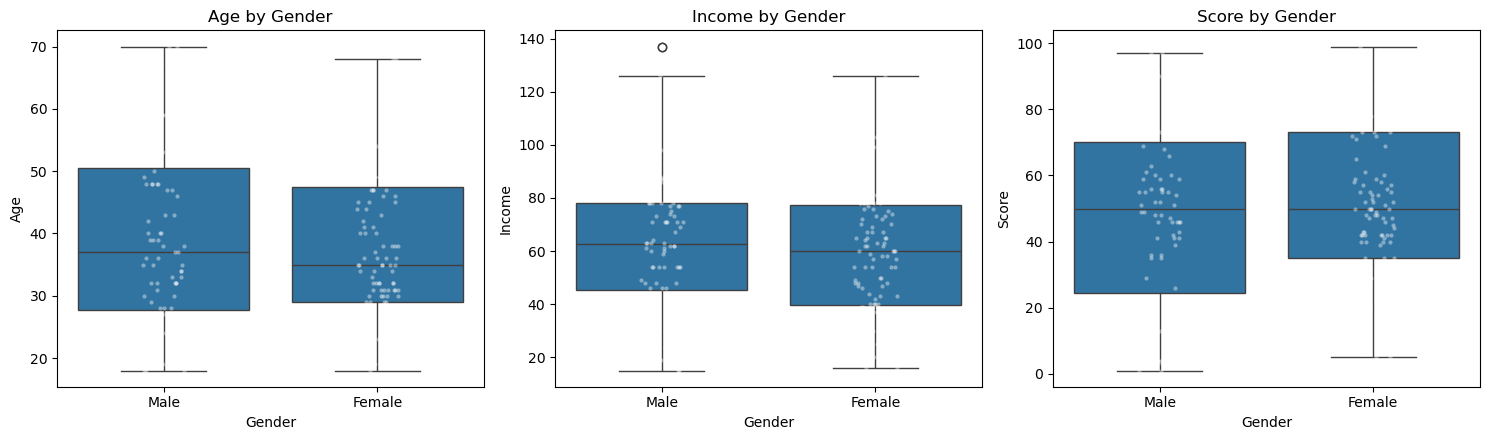

,Age,Income,Score
Gender,,,
Female,38.10,59.25,51.53
Male,39.81,62.23,48.51


In [6]:
# --- Does gender explain anything? ---------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, features):
    sns.boxplot(data=df, x="Gender", y=col, ax=ax)
    sns.stripplot(data=df, x="Gender", y=col, ax=ax, color="white", alpha=0.4, size=3)
    ax.set_title(f"{col} by Gender")
plt.tight_layout()
plt.show()

# numerical check: group means are almost identical
df.groupby("Gender")[features].mean().round(2)

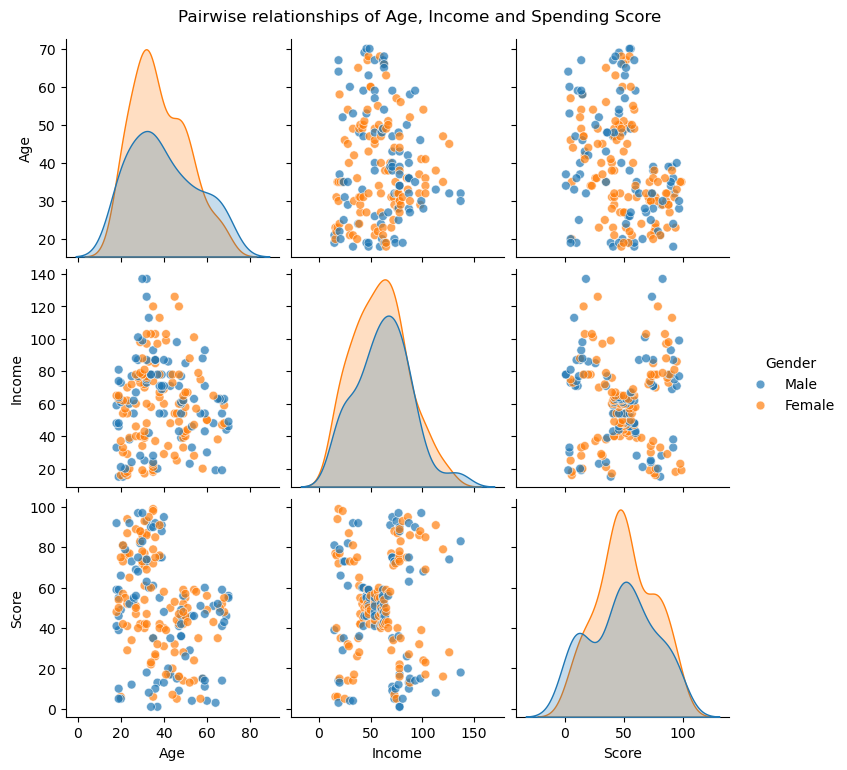

In [7]:
# --- Multivariate view: pairplot -----------------------------------------
sns.pairplot(df[features + ["Gender"]], hue="Gender", diag_kind="kde",
             plot_kws={"alpha": 0.7, "s": 40})
plt.suptitle("Pairwise relationships of Age, Income and Spending Score", y=1.02)
plt.show()

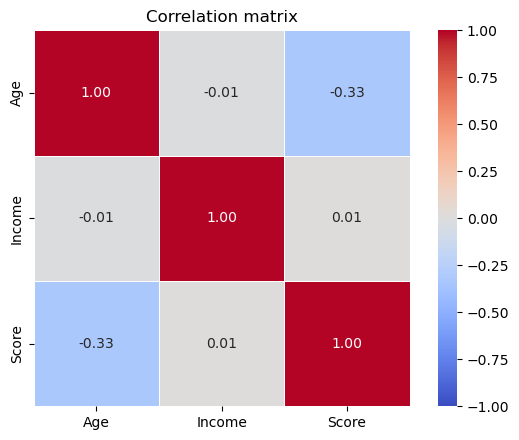

In [8]:
# --- Correlation -----------------------------------------------------------
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

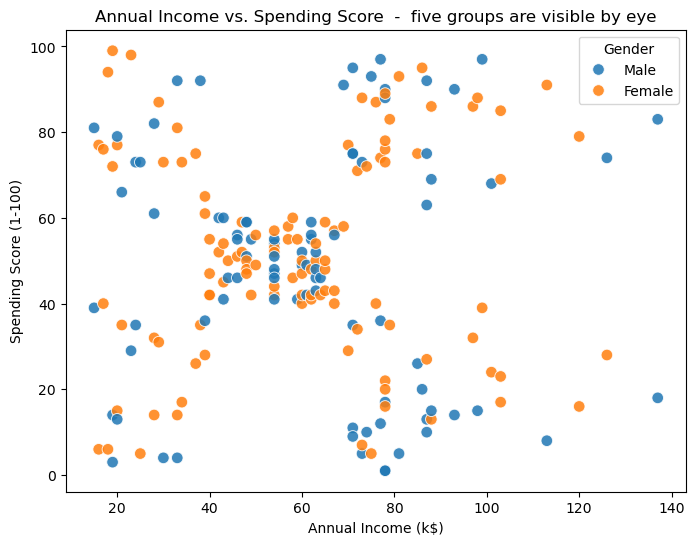

In [9]:
# --- The key plot: Income vs. Spending Score ------------------------------
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Income", y="Score", hue="Gender", s=70, alpha=0.85)
plt.title("Annual Income vs. Spending Score  -  five groups are visible by eye")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

### Findings of the EDA

**Structure & quality**
* 200 rows, 5 columns: `CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`.
* **No missing values, no duplicates.** The data set is already clean, no imputation is needed.
* `CustomerID` is only a running number (1...200) and carries no information &rarr; it is **excluded** from the clustering.
* `Gender` is the only categorical column. Since K-Means/Ward need numerical distances, we do not use it as a
  clustering feature; we use it afterwards to *describe* the clusters.

**Distributions**
* `Age`: 18-70, right-skewed, mean &asymp; 38.9.
* `Income`: 15-137 k\$, slightly right-skewed, mean &asymp; 60.6 k\$.
* `Score`: 1-99, roughly symmetric around 50 - looks almost normal.
* Gender is fairly balanced (112 female / 88 male). The box plots and group means show **almost no difference**
  between the genders in Age, Income or Score &rarr; gender is not a useful segmentation variable here.

**Relationships**
* All pairwise correlations are weak (|r| < 0.35). The strongest is `Age` vs. `Score` with r &asymp; -0.33:
  younger customers tend to have a higher spending score.
* `Income` and `Score` are practically uncorrelated (r &asymp; 0.01) - **but** the scatter plot shows that they are
  clearly **not** unstructured: the points form **five well-separated blobs** (low/low, low/high, middle,
  high/low, high/high).

**Conclusion for the clustering**
The Income-vs-Score plane shows the clearest group structure, so we use it as the main feature pair
(Exercises 2-4). This is exactly the situation clustering is made for: a *linear* measure like correlation sees
nothing, while the *density* structure is obvious. Note that `Income` (15-137) and `Score` (1-99) live on a
comparable numerical range, so we can cluster on the raw values; a `StandardScaler` would be mandatory if the
scales differed strongly (we check this in Exercise 5).

### Brief recap on clustering as a method of unsupervised learning

Clustering is a data mining and statistical technique that groups data points according to similarities. It falls under unsupervised learning, in which data is grouped without predefined labels. The family of clustering algorithms includes connectivity-based, centrroid-based, distribution-based and density-based methods.



* Connectivity-based clustering, such as hierarchical clustering, groups data points based on their connectivity.

* Centroid-based clustering, such as K-Means and K-Mode Clustering, organises data around centroids.

* Distribution-based clustering, such as Gaussian Mixture Models (GMM), finds clusters via statistical distributions

* Density-based clustering, such as DBSCAN, finds clusters based on regions of high density.



Hierarchical clustering groups similar data points based on distance or similarity and generates a dendrogram to visualise hierarchical relationships.



There are two methods:



1. **Agglomerative Clustering:**, also known as a bottom-up approach, starts with individual data points and groups them into clusters.

2. **Divisive Clustering:** This is the reverse of agglomerative clustering; it starts with a single cluster and divides it into smaller clusters.



Hierarchical clustering has the advantage that no predefined number of clusters is required. Instead, analysts can use the dendrogram to determine the best clustering solution based on the level at which different clusters emerge.



**Evaluation metric**



* The silhouette value indicates the average value for all samples. This gives an insight into the density and separation of the clusters formed.



* The [Davies-Bouldin Index](https://scikit-learn.org/stable/modules/clustering.html#davies-bouldin-index) is a measure of the average similarity between each cluster and its most similar cluster. Familiarise yourself with it and use it too.

<h2 style="color:blue">Exercise 2: k Means Clustering</h2>



* Cluster the data appropriately using the k-Means algorithm

* Use two categories each from the set Age, Spending Score and Anual Income, which you relate to each other.

* Decide on the number of clusters using the Elbow method.

* Evaluate the quality of the solution using the silhouette analysis.

* The Davies-Bouldin Index evaluates the quality of the cluster separation. Calculate this as well.

### Import the necessary libraries

In [10]:
import numpy as np # linear algebra

import pandas as pd # data processing

import matplotlib.pyplot as plt 

import matplotlib.cm as cm

import seaborn as sns 

import plotly as py

plt.style.use('https://github.com/dhaitz/matplotlib-stylesheets/raw/master/pitayasmoothie-dark.mplstyle')

import plotly.graph_objs as go

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

import scipy.cluster.hierarchy as shc

from sklearn.metrics import silhouette_samples, silhouette_score, davies_bouldin_score

from mpl_toolkits.mplot3d import Axes3D

import mpl_toolkits.mplot3d 

import warnings

import os

warnings.filterwarnings("ignore")

py.offline.init_notebook_mode(connected = True)

### Helper functions for the silhouette analysis

The task descriptions refer to two functions, `silhouette_analysis_kmeans` and `silhouette_analysis_other`.
We implement them once here and reuse them in Exercises 2-5:

* `silhouette_analysis_kmeans(X, range_n_clusters)` - loops over candidate `k`, fits **KMeans** and draws for
  every `k` the silhouette knife plot (left) next to the resulting clusters (right).
* `silhouette_analysis_other(X, clusterer, ...)` - the same plot for **any** other clusterer
  (`AgglomerativeClustering`, `DBSCAN`), including correct handling of the DBSCAN noise label `-1`.

Both print the two evaluation metrics that are asked for:
* **Silhouette score** - higher is better, range [-1, 1]; measures cohesion vs. separation.
* **Davies-Bouldin index (DBI)** - **lower is better**, range [0, &infin;); average similarity of each cluster to its
  most similar cluster. A low DBI means compact clusters that are far away from each other.

In [11]:
def _silhouette_knife(ax, X, labels, silhouette_avg):
    """Draw the classic silhouette 'knife' plot for a given labelling."""
    unique_labels = np.unique(labels)
    n_clusters = len(unique_labels)
    sample_sil = silhouette_samples(X, labels)

    y_lower = 10
    for i, c in enumerate(unique_labels):
        vals = np.sort(sample_sil[labels == c])
        size_c = vals.shape[0]
        y_upper = y_lower + size_c
        color = cm.nipy_spectral(float(i) / n_clusters)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals,
                         facecolor=color, edgecolor=color, alpha=0.8)
        ax.text(-0.05, y_lower + 0.5 * size_c, str(c))
        y_lower = y_upper + 10

    ax.axvline(x=silhouette_avg, color="red", linestyle="--",
               label=f"average = {silhouette_avg:.3f}")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_ylabel("Cluster label")
    ax.set_yticks([])
    ax.set_xlim([-0.4, 1.0])
    ax.legend(loc="lower right")


def silhouette_analysis_kmeans(X, range_n_clusters, feature_names=("x", "y"), random_state=42):
    """Silhouette analysis + Davies-Bouldin index for KMeans over several k.

    Returns a tidy DataFrame with one row per k.
    """
    results = []
    for n_clusters in range_n_clusters:
        clusterer = KMeans(n_clusters=n_clusters, init="k-means++", n_init=10,
                           random_state=random_state, algorithm="elkan").fit(X)
        cluster_labels = clusterer.labels_

        silhouette_avg = silhouette_score(X, cluster_labels)
        db_index = davies_bouldin_score(X, cluster_labels)
        results.append({"k": n_clusters, "silhouette": silhouette_avg,
                        "davies_bouldin": db_index, "inertia": clusterer.inertia_})

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
        _silhouette_knife(ax1, X, cluster_labels, silhouette_avg)
        ax1.set_title(f"Silhouette plot (k = {n_clusters})")

        colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
        ax2.scatter(X[:, 0], X[:, 1], marker=".", s=200, lw=0, alpha=0.8, c=colors)
        centers = clusterer.cluster_centers_
        ax2.scatter(centers[:, 0], centers[:, 1], marker="o", c="white", alpha=1, s=220)
        for i, c in enumerate(centers):
            ax2.scatter(c[0], c[1], marker=f"${i}$", alpha=1, s=60, c="black")
        ax2.set_title("Clustered data")
        ax2.set_xlabel(feature_names[0])
        ax2.set_ylabel(feature_names[1])

        fig.suptitle(f"KMeans  |  k = {n_clusters}  |  silhouette = {silhouette_avg:.3f}  |  "
                     f"Davies-Bouldin = {db_index:.3f}", fontsize=13, fontweight="bold")
        plt.tight_layout()
        plt.show()

    return pd.DataFrame(results)


def silhouette_analysis_other(X, clusterer, feature_names=("x", "y"), title=""):
    """Silhouette analysis + Davies-Bouldin index for any non-KMeans clusterer.

    Works for AgglomerativeClustering and DBSCAN. DBSCAN noise points (label -1)
    are NOT a cluster: they are excluded from both metrics and drawn as grey x.
    """
    labels = clusterer.fit_predict(X)

    mask = labels != -1                       # True everywhere except for noise
    n_noise = int((~mask).sum())
    n_clusters = len(set(labels[mask]))

    if n_clusters < 2:
        print(f"{title}: only {n_clusters} cluster found -> metrics undefined.")
        return None

    # metrics computed on the real clusters only
    silhouette_avg = silhouette_score(X[mask], labels[mask])
    db_index = davies_bouldin_score(X[mask], labels[mask])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    _silhouette_knife(ax1, X[mask], labels[mask], silhouette_avg)
    ax1.set_title("Silhouette plot" + (" (noise excluded)" if n_noise else ""))

    uniq = np.unique(labels[mask])
    for i, c in enumerate(uniq):
        color = cm.nipy_spectral(float(i) / len(uniq))
        ax2.scatter(X[labels == c, 0], X[labels == c, 1], s=60, alpha=0.85,
                    color=color, label=f"cluster {c}")
    if n_noise:
        ax2.scatter(X[~mask, 0], X[~mask, 1], s=60, marker="x", c="grey",
                    label=f"noise ({n_noise})")
    ax2.set_title("Clustered data")
    ax2.set_xlabel(feature_names[0])
    ax2.set_ylabel(feature_names[1])
    ax2.legend(fontsize=8)

    fig.suptitle(f"{title}  |  clusters = {n_clusters}  |  silhouette = {silhouette_avg:.3f}  |  "
                 f"Davies-Bouldin = {db_index:.3f}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

    return {"labels": labels, "n_clusters": n_clusters, "n_noise": n_noise,
            "silhouette": silhouette_avg, "davies_bouldin": db_index}


def elbow_plot(X, k_max=10, title="Elbow method", random_state=42):
    """Plot inertia (WCSS) over k and return the values."""
    inertias = []
    ks = range(1, k_max + 1)
    for k in ks:
        km = KMeans(n_clusters=k, init="k-means++", n_init=10,
                    random_state=random_state, algorithm="elkan").fit(X)
        inertias.append(km.inertia_)

    plt.figure(figsize=(8, 4.5))
    plt.plot(ks, inertias, "o-", linewidth=2, markersize=8)
    plt.xlabel("Number of clusters k")
    plt.ylabel("Inertia (within-cluster sum of squares)")
    plt.title(title)
    plt.xticks(list(ks))
    plt.grid(alpha=0.3)
    return pd.DataFrame({"k": list(ks), "inertia": inertias})


print("helper functions ready")

helper functions ready


### Summary K- Means Clustering 

### K- means

K-means clustering is an unsupervised machine learning algorithm that groups unlabelled data sets into clusters. The aim is to divide the data points into clusters in which the elements in each group are more similar than those in other groups. The **'K'** in K-Means stands for the number of clusters we want to identify.



**The algorithm works as follows:**

1. we start with a random initialisation of K points, known as cluster centroids.

2. each data point is then assigned to the nearest cluster centroid based on similarity, which is usually calculated using Euclidean distance.

3. the cluster centroids are updated by recalculating their positions based on the average of the data points assigned to each cluster.

4. steps 2 and 3 are repeated for a certain number of iterations or until the centroids no longer change significantly.

5 At the end of the process, clusters are available, with each data point assigned to one of the k clusters.



The initial cluster centroids can be determined randomly or according to certain criteria, e.g. random data points or values within the boundaries of the data set.

<code>clusterer = KMeans(n_clusters = n_clusters, init='k-means++', random_state= 42, algorithm='elkan').fit(X)</code>



This line of code creates a KMeans cluster algorithm and configures it with parameters such as the number of clusters, the initialisation method and the choice of algorithm ("elkan" in this case). This configuration is then used in the `silhouette_analysis_kmeans` function to analyse the data and display the clustering results using silhouette analysis.

### 2.1 First feature pair: **Annual Income vs. Spending Score**

This is the pair with the clearest structure in the EDA. Both features are on a comparable scale
(15-137 vs. 1-99), so we cluster on the raw values.

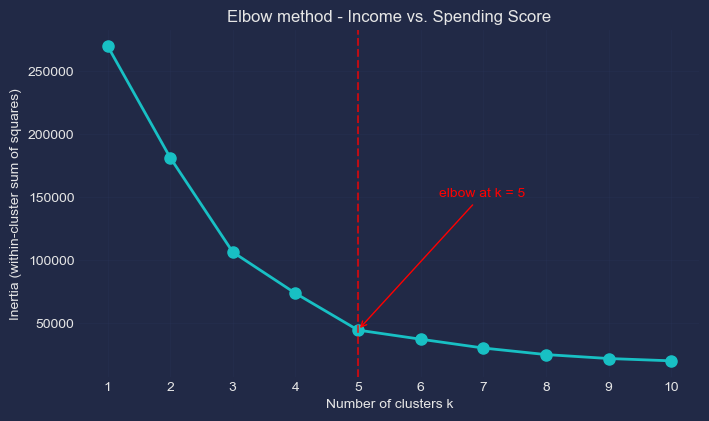

,k,inertia,drop_%
0,1,269981.3,NaN
1,2,181363.6,32.8
2,3,106348.4,41.4
3,4,73679.8,30.7
4,5,44448.5,39.7
5,6,37233.8,16.2
6,7,30241.3,18.8
7,8,25036.4,17.2
8,9,21916.8,12.5
9,10,20072.1,8.4


In [12]:
X_is = df[["Income", "Score"]].values          # "is" = Income / Score

elbow_is = elbow_plot(X_is, k_max=10, title="Elbow method - Income vs. Spending Score")
plt.axvline(5, color="red", linestyle="--", alpha=0.7)
plt.annotate("elbow at k = 5", xy=(5, elbow_is.loc[4, "inertia"]),
             xytext=(6.3, 150000), arrowprops=dict(arrowstyle="->", color="red"), color="red")
plt.show()

# relative drop in inertia -> makes the "kink" objective
elbow_is["drop_%"] = (-elbow_is["inertia"].pct_change() * 100).round(1)
elbow_is.round(1)

The curve falls steeply until `k = 5` and is almost flat afterwards: the inertia drops by **~40 %** when going
from k=4 to k=5, but only by **~16 %** from k=5 to k=6. The "kink" of the elbow therefore lies at **k = 5** -
which matches the five blobs we saw in the EDA scatter plot.

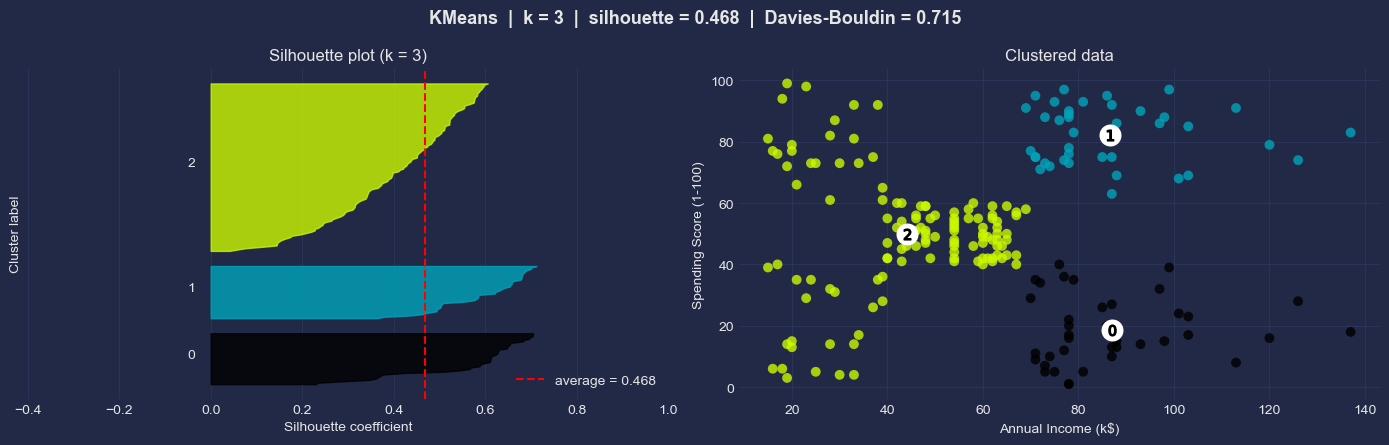

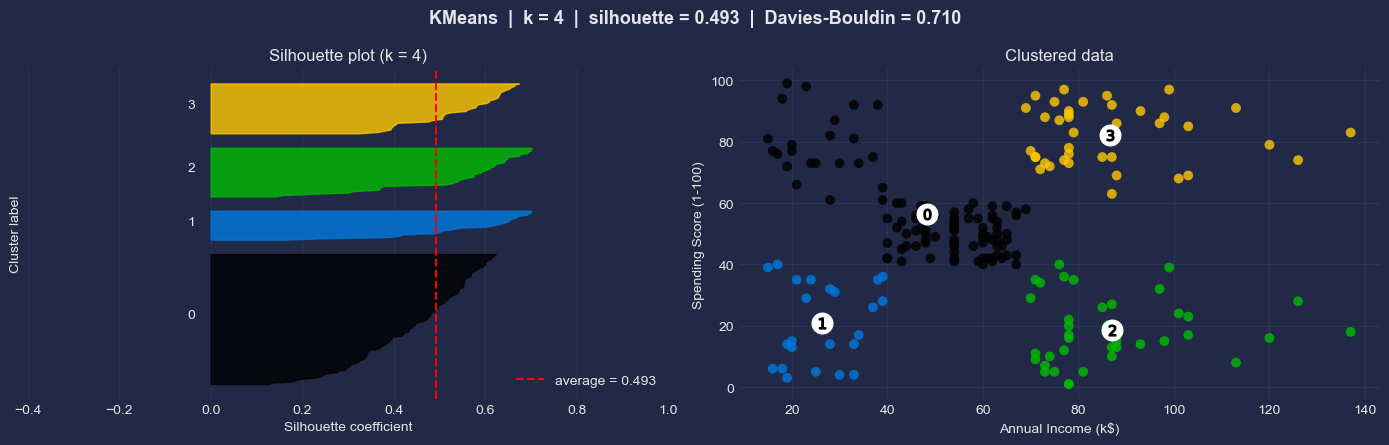

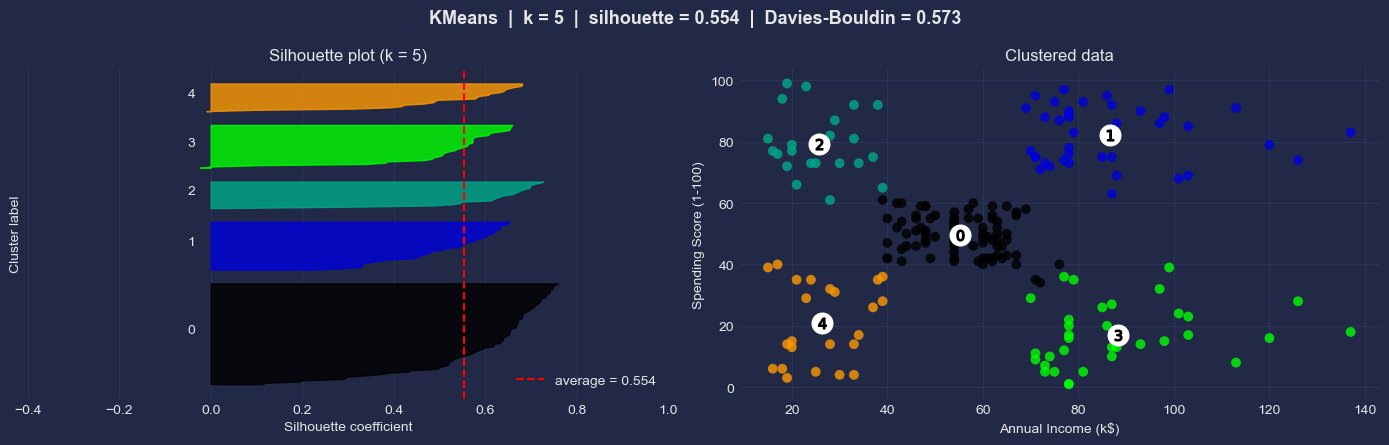

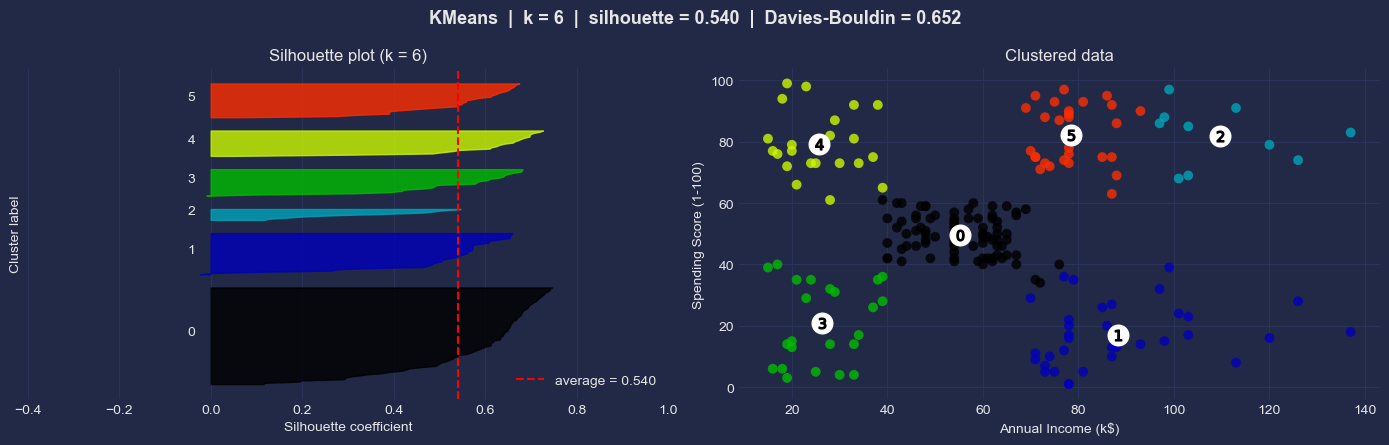

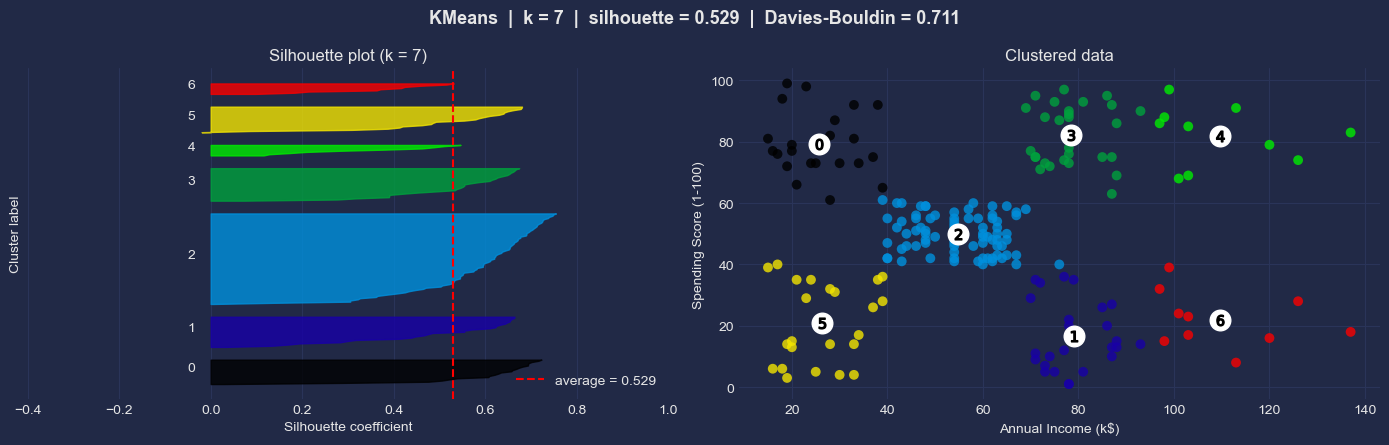

,k,silhouette,davies_bouldin,inertia
0,3,0.468,0.715,106348.373
1,4,0.493,0.710,73679.789
2,5,0.554,0.573,44448.455
3,6,0.540,0.652,37233.815
4,7,0.529,0.711,30241.344


In [13]:
# Silhouette analysis for the candidate values around the elbow
scores_is = silhouette_analysis_kmeans(X_is, range_n_clusters=[3, 4, 5, 6, 7],
                                       feature_names=("Annual Income (k$)", "Spending Score (1-100)"))
scores_is.round(3)

**Reading the silhouette plots**

* `k = 5` gives the **highest average silhouette (0.554)** and the **lowest Davies-Bouldin index (0.573)** -
  both metrics agree.
* At `k = 5` all five knives are roughly **equally wide**, they all reach **beyond the red average line** and
  **no cluster has negative silhouette values** &rarr; every cluster is real and well separated.
* At `k = 3` and `k = 4` some knives are much wider than others (blobs are merged), at `k = 6` / `k = 7` thin
  knives with values below the average appear - a sign that a natural blob is being **split artificially**.

&rarr; **k = 5 is the best solution**, confirmed independently by the elbow, the silhouette and the DBI.

KMeans (Income vs Score), k=5   ->  silhouette = 0.5539   Davies-Bouldin = 0.5726


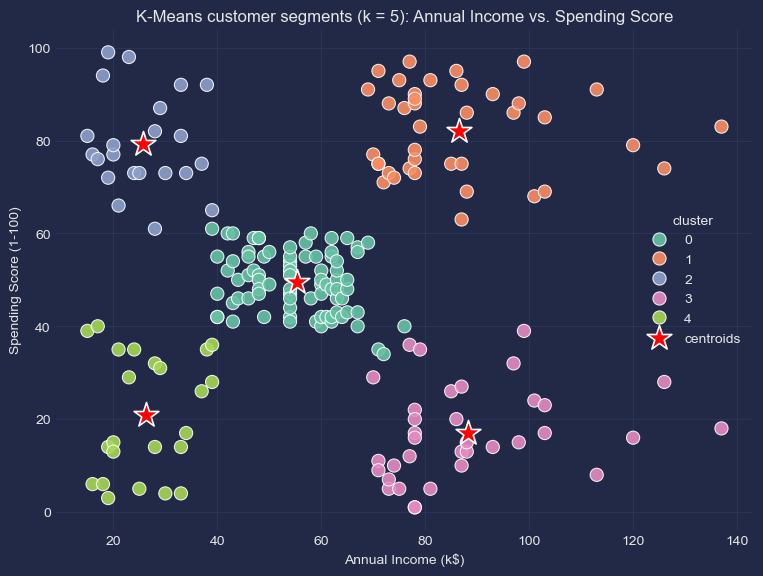

In [14]:
# --- Final model: k = 5 ---------------------------------------------------
km_is = KMeans(n_clusters=5, init="k-means++", n_init=10,
               random_state=42, algorithm="elkan").fit(X_is)
df["cluster_is"] = km_is.labels_

sil_is = silhouette_score(X_is, km_is.labels_)
dbi_is = davies_bouldin_score(X_is, km_is.labels_)
print(f"KMeans (Income vs Score), k=5   ->  silhouette = {sil_is:.4f}   Davies-Bouldin = {dbi_is:.4f}")

plt.figure(figsize=(9, 6.5))
sns.scatterplot(data=df, x="Income", y="Score", hue="cluster_is",
                palette="Set2", s=90, alpha=0.9)
plt.scatter(km_is.cluster_centers_[:, 0], km_is.cluster_centers_[:, 1],
            s=350, c="red", marker="*", edgecolor="white", linewidth=1.2,
            label="centroids", zorder=5)
plt.title("K-Means customer segments (k = 5): Annual Income vs. Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="cluster")
plt.show()

In [15]:
# --- Cluster profile: who is in which segment? ----------------------------
profile_is = (df.groupby("cluster_is")
                .agg(n=("CustomerID", "count"),
                     Age=("Age", "mean"),
                     Income=("Income", "mean"),
                     Score=("Score", "mean"),
                     share_female=("Gender", lambda g: (g == "Female").mean()))
                .round(2))
profile_is["share_female"] = (profile_is["share_female"] * 100).round(1).astype(str) + " %"
profile_is

,n,Age,Income,Score,share_female
cluster_is,,,,,
0,81,42.72,55.30,49.52,59.0 %
1,39,32.69,86.54,82.13,54.0 %
2,22,25.27,25.73,79.36,59.0 %
3,35,41.11,88.20,17.11,46.0 %
4,23,45.22,26.30,20.91,61.0 %


### Business interpretation of the five segments

| Cluster | Income | Score | Size | Name | Marketing action |
|---|---|---|---|---|---|
| **Careless** | low | **high** | ~22 | young, spend more than they earn | loyalty programme, instalments - already engaged |
| **Standard** | middle | middle | ~81 | the big average mass | the "default" customers, cross-selling |
| **Target** | **high** | **high** | ~39 | the ideal customers | **highest priority**: premium offers, VIP programme |
| **Sensible** | **high** | low | ~35 | rich but careful | biggest **untapped potential** - needs targeted incentives |
| **Careful** | low | low | ~23 | low budget, low spending | low priority, discount campaigns |

(The cluster *numbers* depend on the random initialisation - read the table above, not the numbers.)
The two most interesting groups for the shopping centre are **Target** (protect them) and **Sensible**
(they have the money but do not spend it - the largest upside).

### 2.2 Second feature pair: **Age vs. Spending Score**

The task asks for two categories *each* related to one another. `Age` vs. `Score` is the pair with the
strongest (though still weak) correlation, r &asymp; -0.33.

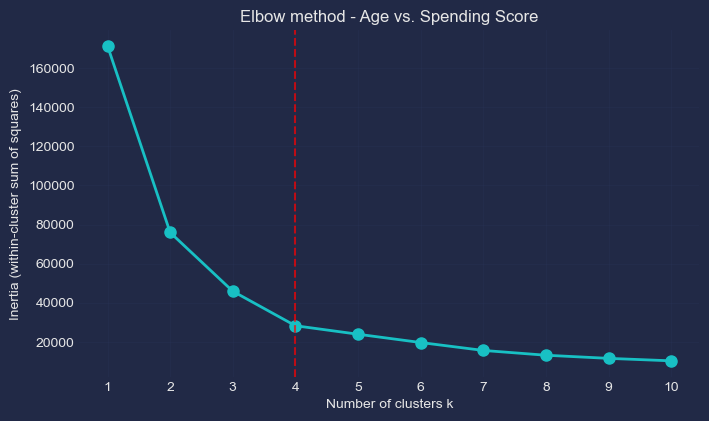

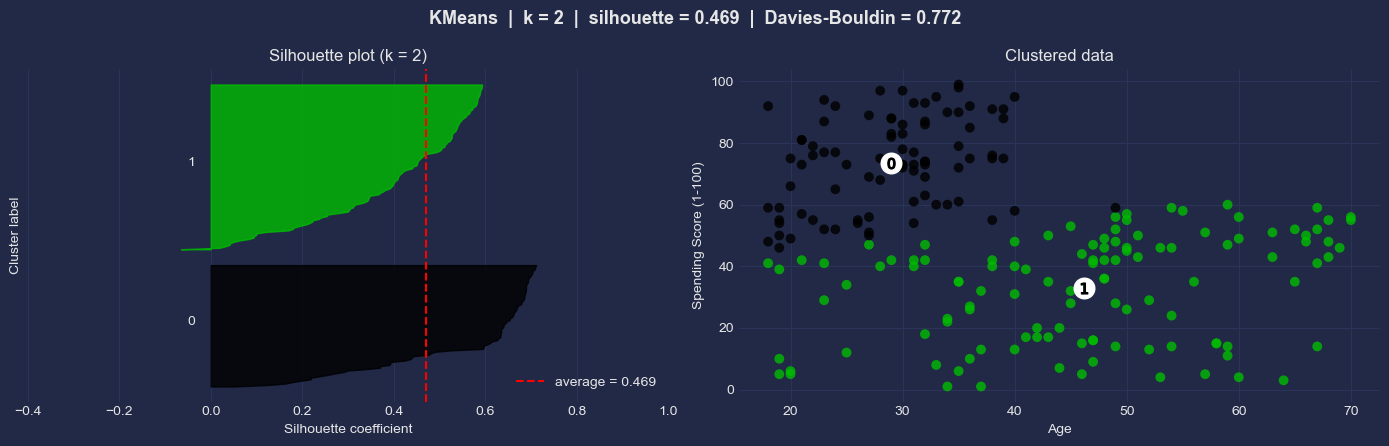

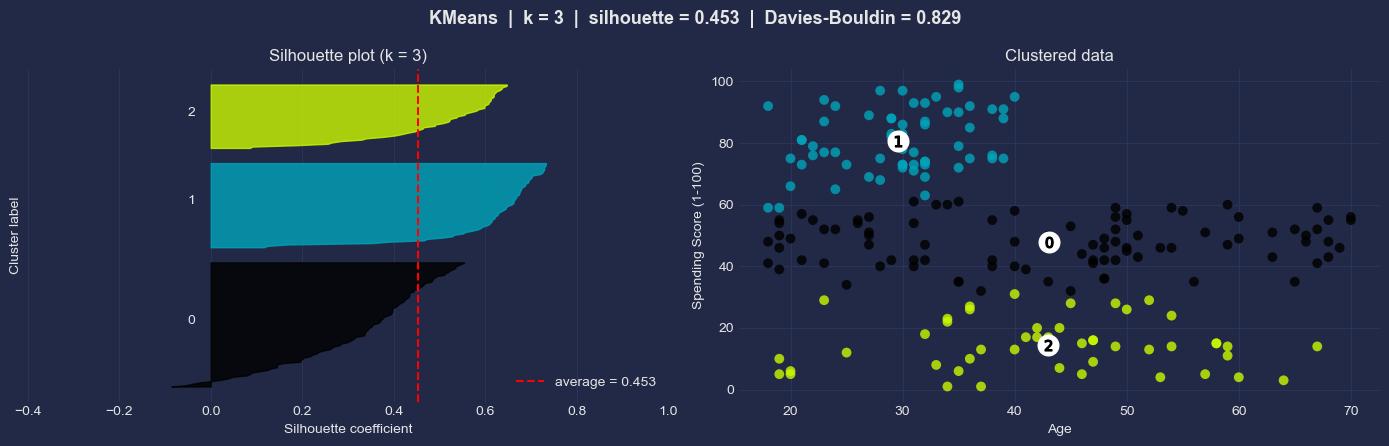

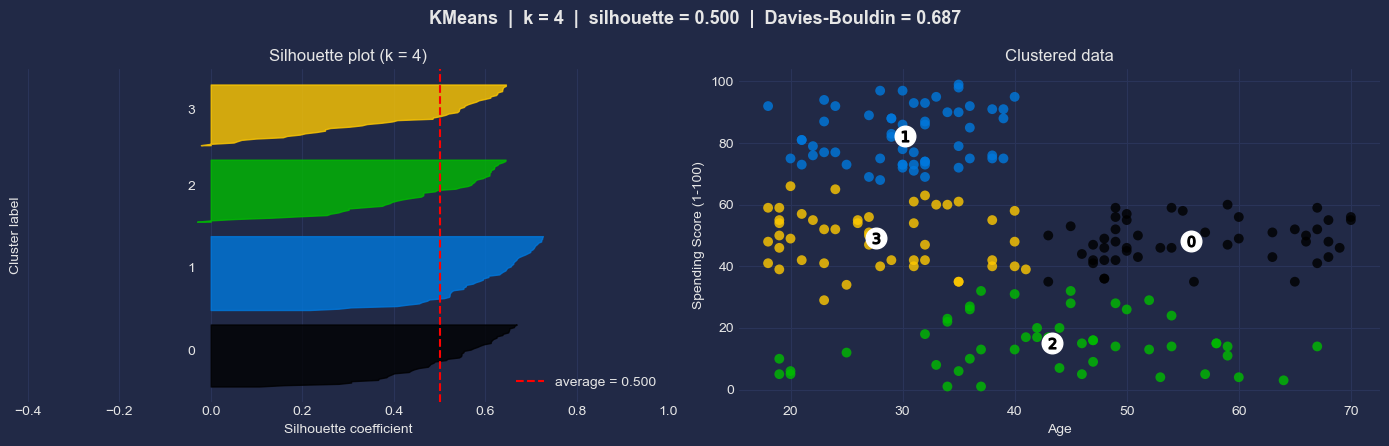

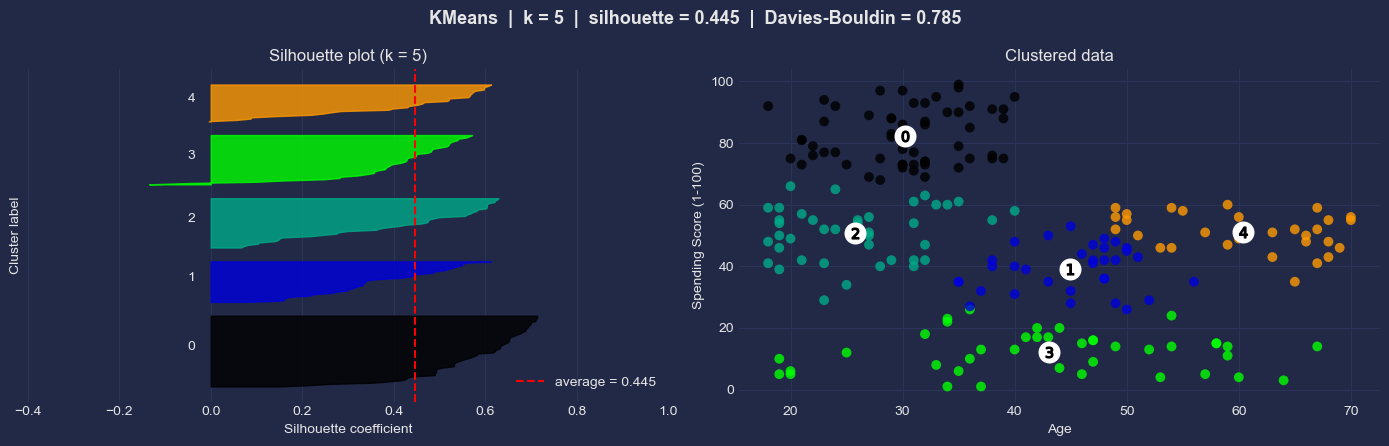

,k,silhouette,davies_bouldin,inertia
0,2,0.469,0.772,75949.156
1,3,0.453,0.829,45840.677
2,4,0.500,0.687,28165.584
3,5,0.445,0.785,23811.524


In [16]:
X_as = df[["Age", "Score"]].values             # "as" = Age / Score

elbow_as = elbow_plot(X_as, k_max=10, title="Elbow method - Age vs. Spending Score")
plt.axvline(4, color="red", linestyle="--", alpha=0.7)
plt.show()

scores_as = silhouette_analysis_kmeans(X_as, range_n_clusters=[2, 3, 4, 5],
                                       feature_names=("Age", "Spending Score (1-100)"))
scores_as.round(3)

In [17]:
# Best solution according to silhouette / DBI: k = 4
km_as = KMeans(n_clusters=4, init="k-means++", n_init=10,
               random_state=42, algorithm="elkan").fit(X_as)
df["cluster_as"] = km_as.labels_

print(f"KMeans (Age vs Score), k=4      ->  silhouette = {silhouette_score(X_as, km_as.labels_):.4f}"
      f"   Davies-Bouldin = {davies_bouldin_score(X_as, km_as.labels_):.4f}")

df.groupby("cluster_as").agg(n=("CustomerID", "count"),
                             Age=("Age", "mean"),
                             Score=("Score", "mean"),
                             Income=("Income", "mean")).round(2)

KMeans (Age vs Score), k=4      ->  silhouette = 0.4997   Davies-Bouldin = 0.6869


,n,Age,Score,Income
cluster_as,,,,
0,48,55.71,48.23,54.77
1,57,30.18,82.35,66.07
2,48,43.29,15.02,66.94
3,47,27.62,49.15,53.28


**Comparison of the two feature pairs**

| feature pair | best k | silhouette | Davies-Bouldin |
|---|---|---|---|
| Income vs. Score | **5** | **0.554** | **0.573** |
| Age vs. Score | 4 | 0.500 | 0.687 |

`Age` vs. `Score` produces *usable* clusters - the split is real: **not a single customer older than 40 has a
spending score above 70** (54 customers have Score > 70, the oldest is exactly 40), so the upper right corner of
that plane is genuinely empty. But the boundaries are **cuts through a continuum**, not
gaps: the silhouette is clearly lower and the DBI higher. **Income vs. Score remains the better basis for the
segmentation** and we continue with it in Exercises 3 and 4.

<h2 style="color:blue">Exercise 3: Agglomerative Hierarchical Clustering</h2>



* Now carry out the analysis as in task 2 using Agglomerative Hierarchical Clustering.

* Evaluate your solution using the silhouette analysis and the Davies-Bouldin index.


### Summary Agglomerative Hierarchical Clustering (Trees)

Agglomerative clustering is a hierarchical clustering technique in which each data point is treated as a single cluster and then cluster pairs are merged until only one cluster remains. This method is based on the bottom-up approach, where clusters are iteratively combined based on their similarity or proximity.



Meaning of the parameters



**Distance metric:** Determines how the similarity between clusters is measured. The distance metric is usually set to **'Euclidean'**.



**Linkage criteria:** Determines the merging strategy that influences the shape and size of the clusters. The **'Ward'** linkage, for example, minimises the variance when merging clusters, resulting in more compact and spherical clusters.



In addition, the number of clusters is an important parameter in agglomerative clustering, which can be controlled with the **dendrogram** visualisation or the **'distance_threshold'** parameter. The parameter "distance_threshold" allows the user to specify the maximum distance at which the clusters are merged, effectively controlling the granularity of the clustering.

<code>clusterer = AgglomerativeClustering(n_clusters=n_clusters, metric= 'euclidean', linkage='ward').fit(X)</code>



This line of code initialises the agglomerative clustering algorithm by specifying the number of clusters (n_clusters), the distance metric (metric) and the linkage criterion (linkage). This code is used in the silhouette_analysis_other function.

### 3.1 Dendrogram - how many clusters does the tree suggest?

The big advantage of hierarchical clustering: we do **not** have to fix `k` in advance. We cut the dendrogram
where the vertical jumps (= merge distances) become large.

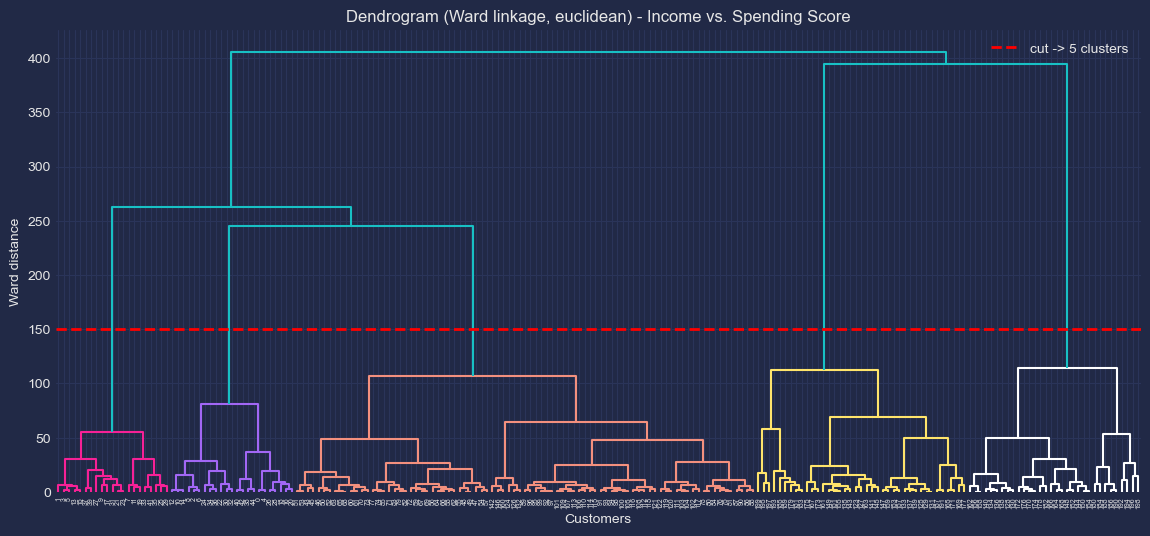

In [18]:
plt.figure(figsize=(14, 6))
dend = shc.dendrogram(shc.linkage(X_is, method="ward"),
                      color_threshold=150)
plt.axhline(y=150, color="red", linestyle="--", linewidth=2,
            label="cut -> 5 clusters")
plt.title("Dendrogram (Ward linkage, euclidean) - Income vs. Spending Score")
plt.xlabel("Customers")
plt.ylabel("Ward distance")
plt.legend()
plt.show()

Cutting the tree at a Ward distance of ~150 crosses **five** vertical lines &rarr; the dendrogram suggests
**k = 5**, exactly like the elbow method in Exercise 2. The five branches are also clearly separated
(long vertical lines before they merge), which is a further hint that these clusters are real.

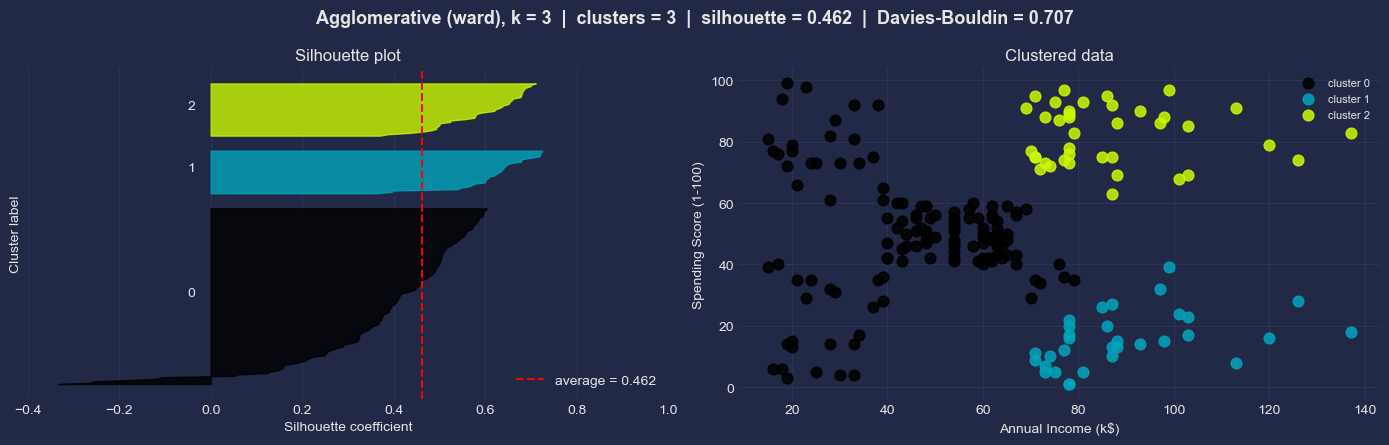

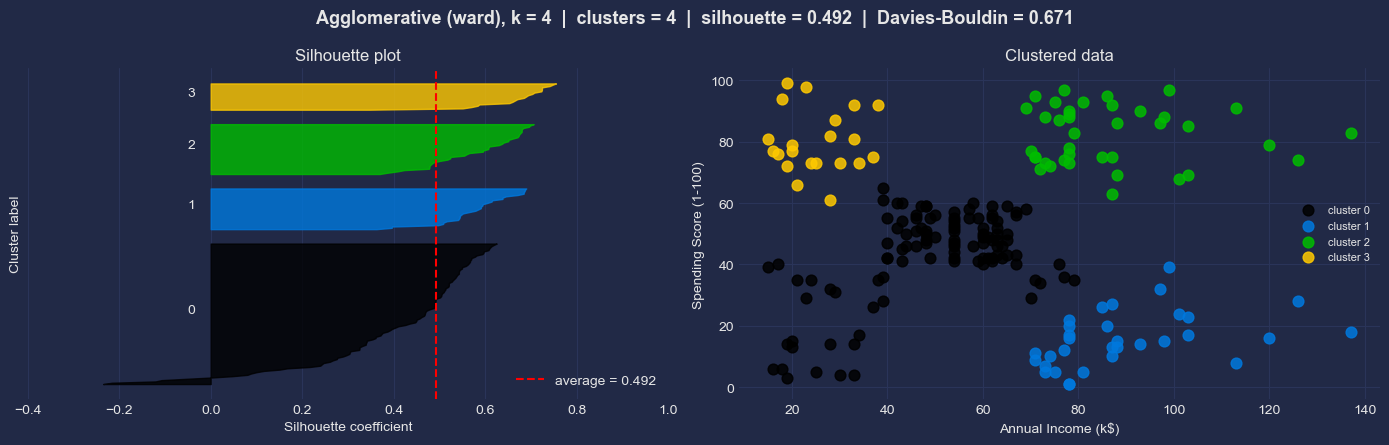

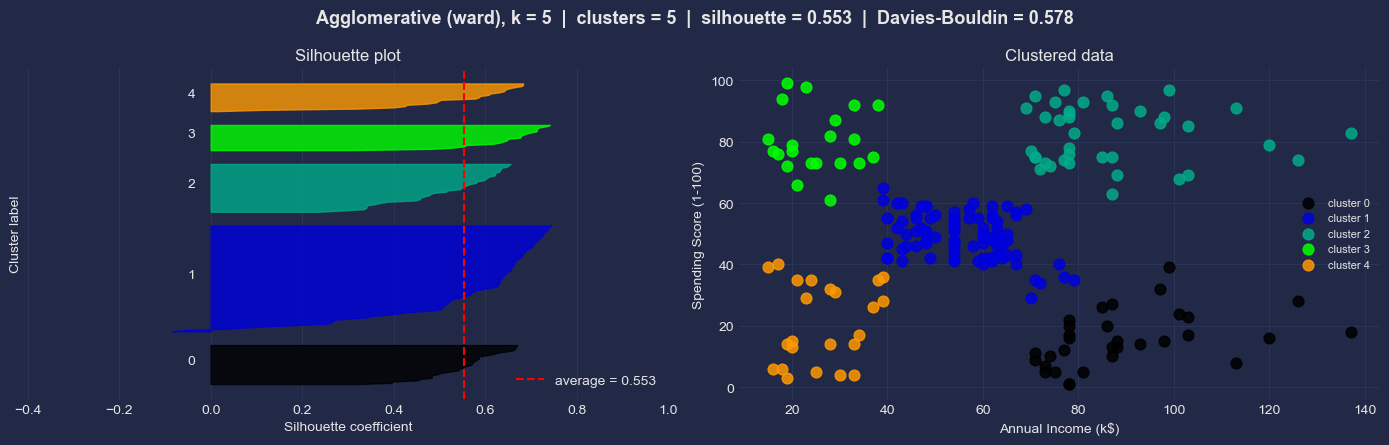

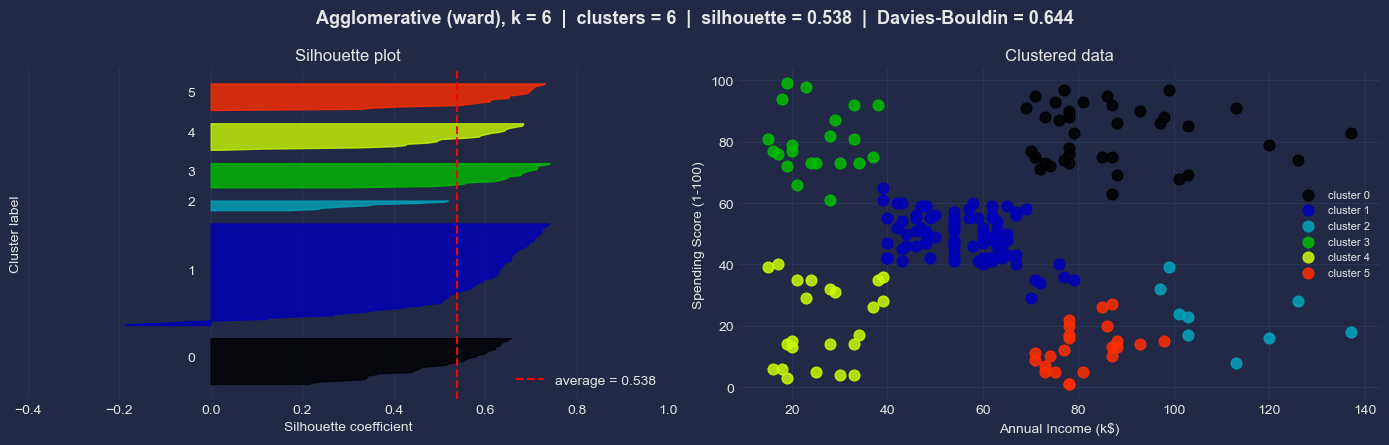

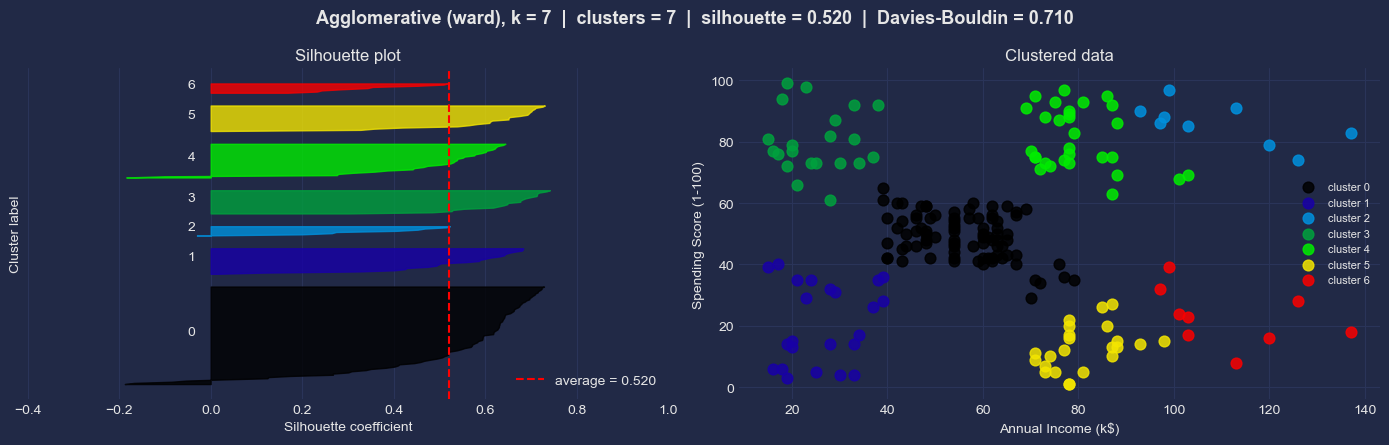

,k,silhouette,davies_bouldin
0,3,0.462,0.707
1,4,0.492,0.671
2,5,0.553,0.578
3,6,0.538,0.644
4,7,0.520,0.710


In [19]:
# --- Silhouette analysis over several k ----------------------------------
agglo_results = []
for k in [3, 4, 5, 6, 7]:
    clusterer = AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage="ward")
    res = silhouette_analysis_other(X_is, clusterer,
                                    feature_names=("Annual Income (k$)", "Spending Score (1-100)"),
                                    title=f"Agglomerative (ward), k = {k}")
    agglo_results.append({"k": k, "silhouette": res["silhouette"],
                          "davies_bouldin": res["davies_bouldin"]})

pd.DataFrame(agglo_results).round(3)

In [20]:
# --- Final model: k = 5 ---------------------------------------------------
agg_is = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage="ward").fit(X_is)
df["cluster_agg"] = agg_is.labels_

sil_agg = silhouette_score(X_is, agg_is.labels_)
dbi_agg = davies_bouldin_score(X_is, agg_is.labels_)
print(f"Agglomerative (ward), k=5       ->  silhouette = {sil_agg:.4f}   Davies-Bouldin = {dbi_agg:.4f}")
print(f"KMeans               , k=5       ->  silhouette = {sil_is:.4f}   Davies-Bouldin = {dbi_is:.4f}")

# Do both methods find the same customers? (cluster numbers differ, the grouping is what counts)
print("\nCross tabulation KMeans vs. Agglomerative:")
ct = pd.crosstab(df["cluster_is"], df["cluster_agg"],
                 rownames=["KMeans"], colnames=["Agglomerative"])
print(ct)

agreement = ct.max(axis=1).sum() / len(df)
print(f"\n-> {agreement:.1%} of the customers land in the same segment in both methods.")

Agglomerative (ward), k=5       ->  silhouette = 0.5530   Davies-Bouldin = 0.5782
KMeans               , k=5       ->  silhouette = 0.5539   Davies-Bouldin = 0.5726

Cross tabulation KMeans vs. Agglomerative:
Agglomerative   0   1   2   3   4
KMeans                           
0               0  81   0   0   0
1               0   0  39   0   0
2               0   1   0  21   0
3              32   3   0   0   0
4               0   0   0   0  23

-> 98.0% of the customers land in the same segment in both methods.


**Result of Exercise 3**

* The dendrogram independently confirms **k = 5**.
* Silhouette **0.553** and DBI **0.578** are practically identical to K-Means (0.554 / 0.573).
* The cross tabulation shows that each K-Means cluster maps to almost exactly one Ward cluster: **~98 %** of
  the customers get the same segment. Only a handful of points on the borders between blobs are swapped.

This agreement is a **strong validation**: two algorithms with completely different mechanics (centroid-based
vs. bottom-up merging) find the same structure. The segmentation is a property of the *data*, not an artefact
of the algorithm. Ward is marginally worse on the silhouette here because it optimises variance *while merging*
and cannot move a point to another cluster afterwards, as K-Means does in every iteration.

<h2 style="color:blue">Exercise 4: Clustering with DBSCAN</h2>



* Now carry out the analysis as in task 2 with DBSCAN.

* Evaluate your solution using the silhouette analysis and the Davies-Bouldin index.

### Summary DBSCAN

Density-Based Spatial Clustering of Applications with Noise (DBSCAN) is a method that identifies dense regions separated by areas of lower point density. Clusters in DBSCAN are defined as points within a neighbourhood radius that contain at least one point.



Two important parameters in DBSCAN are:



* **eps:** The maximum distance between two samples so that one can be considered to be in the neighbourhood of the other.

**min_samples:** The minimum number of samples in a neighbourhood for a point to be considered a core point.



The selection of these parameters has a significant impact on the effectiveness of DBSCAN. eps controls the size of the neighbourhood, which influences the cluster density, while min_samples controls the robustness of the cluster by determining the minimum number of points required to form a dense region. Fine-tuning these parameters is crucial for achieving the best clustering results.

<code>clusterer = DBSCAN(eps=10, min_samples=3).fit(X)</code>



Diese Codezeile initialisiert den DBSCAN-Algorithmus mit Parametern für den Abstand (eps) und die Mindeststichproben (min_samples). Diese Parameter werden durch Ausprobieren angepasst, um die Clusterbildung zu optimieren. Dieses Codesegment wird innerhalb der Funktion silhouette_analysis_other verwendet.

### 4.1 Choosing `eps` with the k-distance graph

`eps` should not be guessed. The standard procedure: plot the distance to the `min_samples`-th nearest
neighbour for every point, sorted. The **knee** of that curve is a good `eps` - below it we are inside a
cluster, above it we are in empty space.

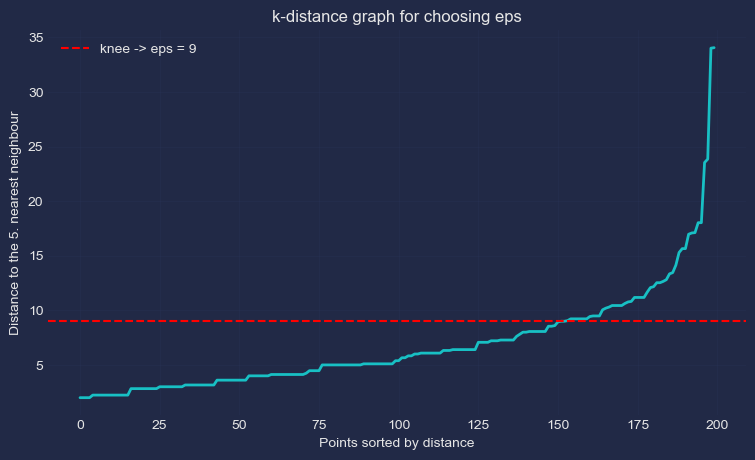

Percentiles of the k-distance: {50: np.float64(5.39), 75: np.float64(8.69), 90: np.float64(12.09), 95: np.float64(15.65), 100: np.float64(34.06)}


In [21]:
from sklearn.neighbors import NearestNeighbors

min_samples = 5
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_is)
distances, _ = nn.kneighbors(X_is)
k_dist = np.sort(distances[:, -1])          # distance to the 5th neighbour

plt.figure(figsize=(9, 5))
plt.plot(k_dist, linewidth=2)
plt.axhline(y=9, color="red", linestyle="--", label="knee -> eps = 9")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to the {min_samples}. nearest neighbour")
plt.title("k-distance graph for choosing eps")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Percentiles of the k-distance:",
      dict(zip([50, 75, 90, 95, 100], np.percentile(k_dist, [50, 75, 90, 95, 100]).round(2))))

In [22]:
# --- Systematic grid search instead of pure trial and error --------------
rows = []
for eps in [5, 6, 7, 8, 9, 10, 11, 12]:
    for ms in [3, 4, 5, 6]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_is)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        n_noise = int((~mask).sum())
        if n_clusters < 2:
            continue
        rows.append({"eps": eps, "min_samples": ms, "clusters": n_clusters,
                     "noise": n_noise, "noise_%": round(100 * n_noise / len(X_is), 1),
                     "silhouette": silhouette_score(X_is[mask], labels[mask]),
                     "davies_bouldin": davies_bouldin_score(X_is[mask], labels[mask])})

grid = pd.DataFrame(rows).round(3)
# a good solution: ~5 clusters, little noise, high silhouette
grid.sort_values("silhouette", ascending=False).head(12)

,eps,min_samples,clusters,noise,noise_%,silhouette,davies_bouldin
2,5,5,5,87,43.5,0.618,0.396
3,5,6,4,100,50.0,0.613,0.402
7,6,6,6,76,38.0,0.586,0.468
1,5,4,7,76,38.0,0.571,0.467
15,8,6,5,47,23.5,0.567,0.469
14,8,5,6,35,17.5,0.565,0.461
6,6,5,7,70,35.0,0.562,0.500
11,7,6,6,69,34.5,0.561,0.518
18,9,5,6,23,11.5,0.557,0.513
10,7,5,6,50,25.0,0.531,0.556


The grid shows the central trade-off of DBSCAN: the combinations with the *highest* silhouette
(e.g. `eps = 5`, `min_samples = 5`, silhouette 0.618) reach that score only by declaring **87 of 200 customers
(43 %) as noise** - they keep the dense cores and throw the rest away. That is not a usable segmentation for a
marketing department: we cannot tell 43 % of our customers "you have no segment".

We therefore choose the knee value from the k-distance graph, **`eps = 9`, `min_samples = 5`**: it produces
6 clusters with only 23 noise points (11.5 %) and still a silhouette of ~0.56.

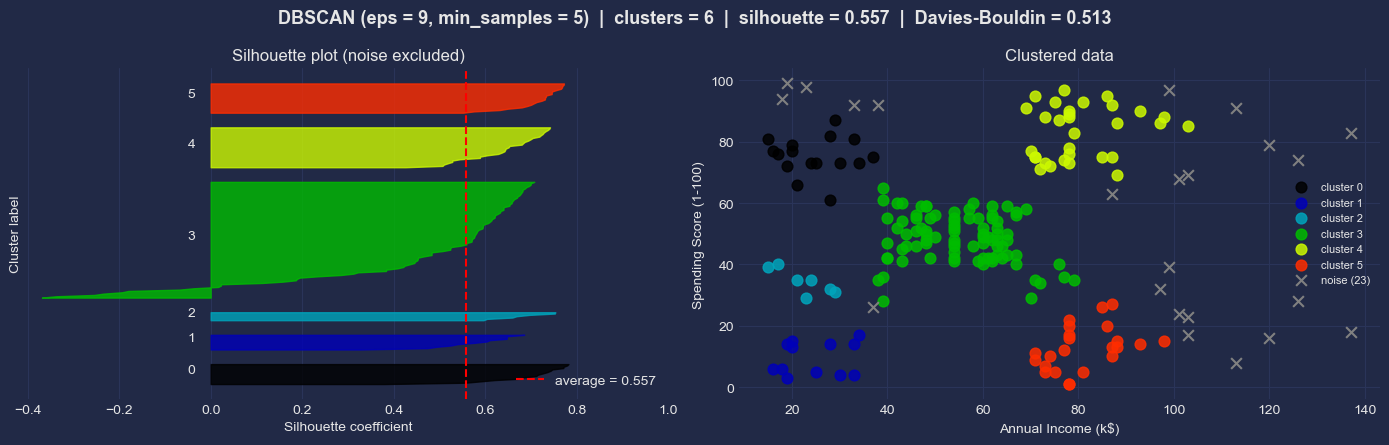

clusters found : 6
noise points   : 23  (11.5%)
silhouette     : 0.5567   (noise excluded)
Davies-Bouldin : 0.5134   (noise excluded)

Cluster sizes (-1 = noise):
cluster_db
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64


In [23]:
# --- Final DBSCAN model ---------------------------------------------------
db = DBSCAN(eps=9, min_samples=5)
res_db = silhouette_analysis_other(X_is, db,
                                   feature_names=("Annual Income (k$)", "Spending Score (1-100)"),
                                   title="DBSCAN (eps = 9, min_samples = 5)")

df["cluster_db"] = res_db["labels"]
print(f"clusters found : {res_db['n_clusters']}")
print(f"noise points   : {res_db['n_noise']}  ({res_db['n_noise'] / len(df):.1%})")
print(f"silhouette     : {res_db['silhouette']:.4f}   (noise excluded)")
print(f"Davies-Bouldin : {res_db['davies_bouldin']:.4f}   (noise excluded)")

print("\nCluster sizes (-1 = noise):")
print(df["cluster_db"].value_counts().sort_index())

In [24]:
# --- Honest comparison: what happens if noise counts as a cluster? -------
labels_db = df["cluster_db"].values
print("DBSCAN metrics WITH noise treated as an own 'cluster' (methodically wrong, but instructive):")
print(f"  silhouette     = {silhouette_score(X_is, labels_db):.4f}")
print(f"  Davies-Bouldin = {davies_bouldin_score(X_is, labels_db):.4f}")
print("\nThe silhouette collapses because the noise points are scattered over the whole plane")
print("and can never be 'compact' - which is exactly why we exclude them above.")

DBSCAN metrics WITH noise treated as an own 'cluster' (methodically wrong, but instructive):
  silhouette     = 0.4360
  Davies-Bouldin = 1.3304

The silhouette collapses because the noise points are scattered over the whole plane
and can never be 'compact' - which is exactly why we exclude them above.


**Result of Exercise 4 - why DBSCAN is the weakest method for this data set**

| method | clusters | silhouette | DBI | customers assigned |
|---|---|---|---|---|
| K-Means (k=5) | 5 | 0.554 | 0.573 | **200 / 200** |
| Agglomerative (k=5) | 5 | 0.553 | 0.578 | **200 / 200** |
| DBSCAN (eps=9, ms=5) | 6 | 0.557 | 0.513 | 177 / 200 |

At first sight DBSCAN looks competitive (silhouette 0.557, even the best DBI). **This comparison is unfair**,
though: DBSCAN is allowed to *drop* the 23 hardest points and computes its score only on the easy remaining
ones. K-Means has to place *every* customer, including the ones between the blobs. Metrics computed on
different subsets cannot be compared directly.

**Why DBSCAN does not fit here:**
* The five blobs have **similar density** and are separated by *thin* gaps rather than empty space. DBSCAN's
  strength - finding arbitrarily shaped clusters of *different* shape in noise - is not needed.
* The customers in the middle blob are dense, so a single `eps` either merges neighbouring blobs (`eps` &ge; 11
  &rarr; only 2-3 clusters) or shreds the sparse ones into noise (`eps` &le; 5 &rarr; 43 % noise). There is no
  `eps` that works for all five groups at once.
* Business-wise, "noise" is not an acceptable segment: those 23 customers still need to be marketed to.

**When DBSCAN *would* win:** non-convex clusters (rings, spirals), real outliers to be detected, or an unknown
number of clusters. For compact, convex, similarly sized blobs - our case - **K-Means is the right tool**.

<h2 style="color:blue">Exercise 5 k Means Clustering with 3 dimensions</h2>



* Now carry out the analysis as in task 2 using the KMeans algorithm and segment Age, Anual Income and Spending Score (3 dimensions)

* Evaluate your solution using the silhouette analysis and the Davies-Bouldin index.

### 5.1 Elbow and silhouette in three dimensions

Now all three variables at once: `Age`, `Annual Income` and `Spending Score`. Their ranges (18-70, 15-137,
1-99) are of the same order of magnitude, so we again cluster on the raw values - we verify this decision with
a scaled model at the end of the exercise.

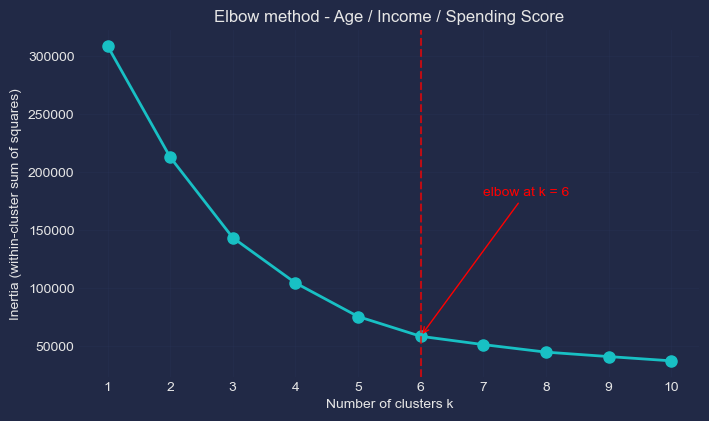

,k,inertia,drop_%
0,1,308812.8,NaN
1,2,212840.2,31.1
2,3,143342.8,32.7
3,4,104366.2,27.2
4,5,75350.8,27.8
5,6,58300.4,22.6
6,7,51133.0,12.3
7,8,44640.0,12.7
8,9,40809.8,8.6
9,10,37128.0,9.0


In [25]:
X_3d = df[["Age", "Income", "Score"]].values

elbow_3d = elbow_plot(X_3d, k_max=10, title="Elbow method - Age / Income / Spending Score")
plt.axvline(6, color="red", linestyle="--", alpha=0.7)
plt.annotate("elbow at k = 6", xy=(6, elbow_3d.loc[5, "inertia"]),
             xytext=(7, 180000), arrowprops=dict(arrowstyle="->", color="red"), color="red")
plt.show()

elbow_3d["drop_%"] = (-elbow_3d["inertia"].pct_change() * 100).round(1)
elbow_3d.round(1)

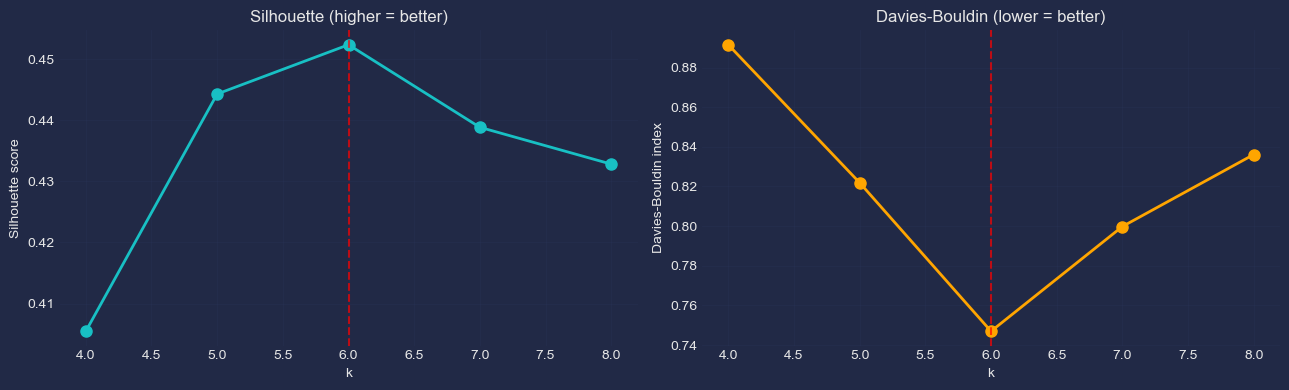

,k,silhouette,davies_bouldin
0,4,0.405,0.891
1,5,0.444,0.822
2,6,0.452,0.747
3,7,0.439,0.800
4,8,0.433,0.836


In [26]:
# Silhouette analysis in 3D. NOTE: the scatter panel of the helper only shows
# the first two dimensions (Age vs Income) - the metrics are computed on all three.
scores_3d = []
for k in [4, 5, 6, 7, 8]:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42, algorithm="elkan").fit(X_3d)
    scores_3d.append({"k": k,
                      "silhouette": silhouette_score(X_3d, km.labels_),
                      "davies_bouldin": davies_bouldin_score(X_3d, km.labels_)})
scores_3d = pd.DataFrame(scores_3d)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(scores_3d["k"], scores_3d["silhouette"], "o-", linewidth=2, markersize=8)
ax1.axvline(6, color="red", linestyle="--", alpha=0.7)
ax1.set_xlabel("k"); ax1.set_ylabel("Silhouette score"); ax1.set_title("Silhouette (higher = better)")
ax1.grid(alpha=0.3)
ax2.plot(scores_3d["k"], scores_3d["davies_bouldin"], "o-", linewidth=2, markersize=8, color="orange")
ax2.axvline(6, color="red", linestyle="--", alpha=0.7)
ax2.set_xlabel("k"); ax2.set_ylabel("Davies-Bouldin index"); ax2.set_title("Davies-Bouldin (lower = better)")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

scores_3d.round(3)

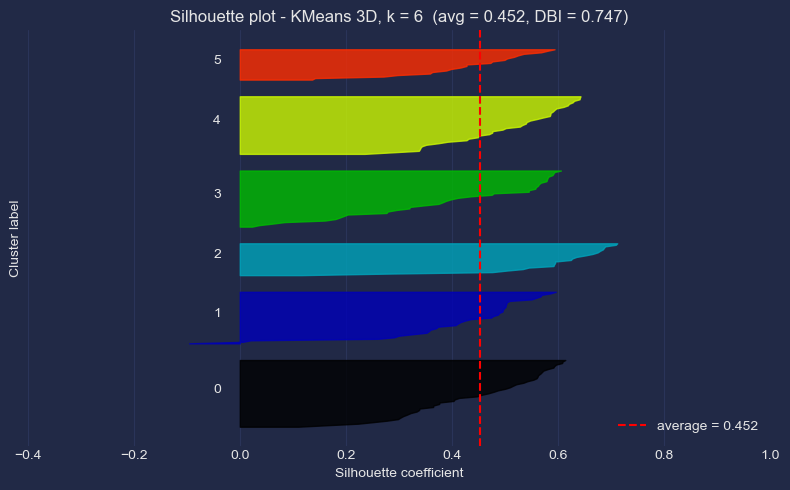

KMeans 3D, k=6  ->  silhouette = 0.4523   Davies-Bouldin = 0.7470


In [27]:
# The silhouette knife plot for the winner k = 6
km_3d = KMeans(n_clusters=6, init="k-means++", n_init=10, random_state=42, algorithm="elkan").fit(X_3d)
df["cluster_3d"] = km_3d.labels_

sil_3d = silhouette_score(X_3d, km_3d.labels_)
dbi_3d = davies_bouldin_score(X_3d, km_3d.labels_)

fig, ax = plt.subplots(figsize=(8, 5))
_silhouette_knife(ax, X_3d, km_3d.labels_, sil_3d)
ax.set_title(f"Silhouette plot - KMeans 3D, k = 6  (avg = {sil_3d:.3f}, DBI = {dbi_3d:.3f})")
plt.tight_layout()
plt.show()

print(f"KMeans 3D, k=6  ->  silhouette = {sil_3d:.4f}   Davies-Bouldin = {dbi_3d:.4f}")

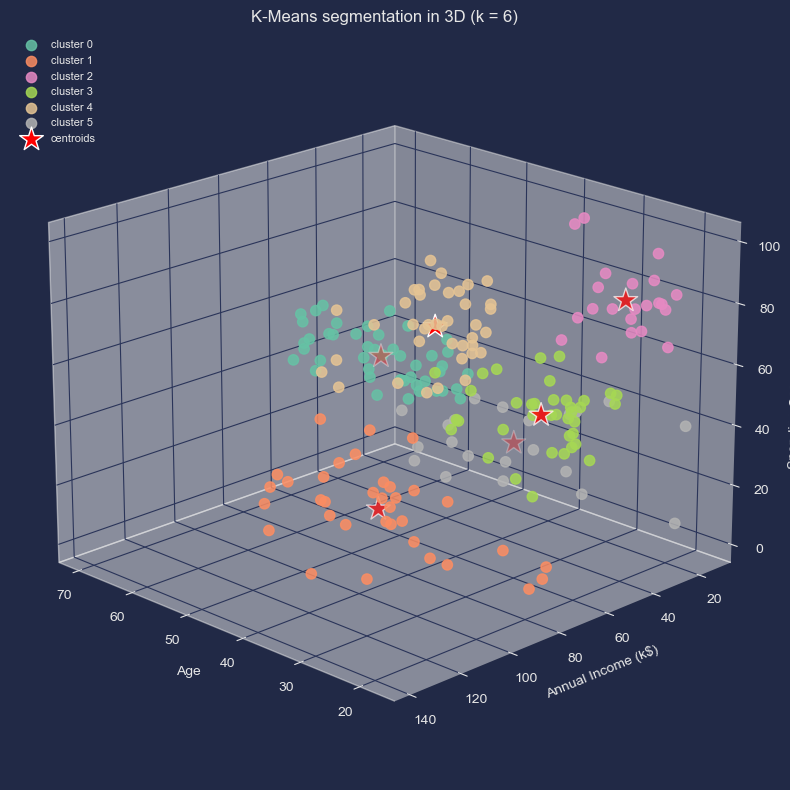

In [28]:
# --- Static 3D view (matplotlib) -----------------------------------------
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

palette = cm.Set2(np.linspace(0, 1, 6))
for c in range(6):
    m = df["cluster_3d"] == c
    ax.scatter(df.loc[m, "Age"], df.loc[m, "Income"], df.loc[m, "Score"],
               s=55, alpha=0.85, color=palette[c], label=f"cluster {c}")

ax.scatter(km_3d.cluster_centers_[:, 0], km_3d.cluster_centers_[:, 1], km_3d.cluster_centers_[:, 2],
           s=320, c="red", marker="*", edgecolor="white", label="centroids")
ax.set_xlabel("Age")
ax.set_ylabel("Annual Income (k$)")
ax.set_zlabel("Spending Score (1-100)")
ax.set_title("K-Means segmentation in 3D (k = 6)")
ax.view_init(elev=20, azim=135)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [29]:
# --- Interactive 3D view (plotly) - drag to rotate -----------------------
trace = go.Scatter3d(
    x=df["Age"], y=df["Income"], z=df["Score"],
    mode="markers",
    marker=dict(color=df["cluster_3d"], size=6, colorscale="Portland",
                opacity=0.85, line=dict(color="white", width=0.4)),
    text=[f"Cluster {c}<br>Age {a}<br>Income {i}k$<br>Score {s}"
          for c, a, i, s in zip(df["cluster_3d"], df["Age"], df["Income"], df["Score"])],
    hoverinfo="text")

layout = go.Layout(
    title="Customer segments in 3D (Age / Income / Spending Score)",
    width=900, height=700,
    scene=dict(xaxis=dict(title="Age"),
               yaxis=dict(title="Annual Income (k$)"),
               zaxis=dict(title="Spending Score (1-100)")))

go.Figure(data=[trace], layout=layout).show()

In [30]:
# --- Profile of the six 3D segments --------------------------------------
profile_3d = (df.groupby("cluster_3d")
                .agg(n=("CustomerID", "count"),
                     Age=("Age", "mean"),
                     Income=("Income", "mean"),
                     Score=("Score", "mean"),
                     share_female=("Gender", lambda g: (g == "Female").mean()))
                .round(1))
profile_3d["share_female"] = (profile_3d["share_female"] * 100).round(1).astype(str) + " %"
profile_3d

,n,Age,Income,Score,share_female
cluster_3d,,,,,
0,45,56.2,53.4,49.1,60.0 %
1,35,41.7,88.2,17.3,40.0 %
2,22,25.3,25.7,79.4,60.0 %
3,38,27.0,56.7,49.1,70.0 %
4,39,32.7,86.5,82.1,50.0 %
5,21,44.1,25.1,19.5,60.0 %


In [31]:
# What did the third dimension actually add? Compare the 2D and the 3D solution
print("2D segments (Income x Score)  vs.  3D segments (Age x Income x Score):")
pd.crosstab(df["cluster_is"], df["cluster_3d"],
            rownames=["2D cluster"], colnames=["3D cluster"])

2D segments (Income x Score)  vs.  3D segments (Age x Income x Score):


3D cluster,0,1,2,3,4,5
2D cluster,,,,,,
0,43,1,0,37,0,0
1,0,0,0,0,39,0
2,0,0,22,0,0,0
3,0,34,0,1,0,0
4,2,0,0,0,0,21


In [32]:
# --- Check: does scaling change the picture? -----------------------------
from sklearn.preprocessing import StandardScaler

X_3d_scaled = StandardScaler().fit_transform(X_3d)

rows = []
for k in [4, 5, 6, 7, 8]:
    km_s = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42, algorithm="elkan").fit(X_3d_scaled)
    rows.append({"k": k,
                 "silhouette_scaled": silhouette_score(X_3d_scaled, km_s.labels_),
                 "davies_bouldin_scaled": davies_bouldin_score(X_3d_scaled, km_s.labels_)})

comparison = pd.DataFrame(rows).merge(scores_3d, on="k", suffixes=("", "_raw"))
comparison = comparison[["k", "silhouette", "silhouette_scaled", "davies_bouldin", "davies_bouldin_scaled"]]
print("raw vs. standardised features (3D):")
comparison.round(3)

raw vs. standardised features (3D):


,k,silhouette,silhouette_scaled,davies_bouldin,davies_bouldin_scaled
0,4,0.405,0.404,0.891,0.931
1,5,0.444,0.417,0.822,0.875
2,6,0.452,0.428,0.747,0.825
3,7,0.439,0.417,0.800,0.793
4,8,0.433,0.408,0.836,0.892


Standardising the features lowers the silhouette slightly (the raw scale already weights `Income`, the variable
with the widest spread, a bit more strongly - which happens to help here), but the **silhouette optimum stays at
k = 6** in both cases. Only the scaled DBI marginally prefers k = 7 (0.793) over k = 6 (0.825) - a difference far
too small to overrule the silhouette and the elbow, which both point at 6.
Our decision to cluster the raw values is therefore not driving the result. If the features had
very different units (e.g. income in \$ instead of k\$), scaling would be **mandatory**, because K-Means uses
euclidean distances and the variable with the largest numerical range would dominate them completely.

### 5.2 Interpretation of the six 3D segments

Adding `Age` **splits the two "middle income / middle score" halves apart** and refines the target group: the
2D "Standard" cluster (~81 customers) breaks into a **younger** and an **older** average customer, and the
"Target" group turns out to be almost exclusively **young** (~33 years). Read the profile table above:

| typical segment | n | Age | Income | Score | Marketing meaning |
|---|---|---|---|---|---|
| young / high income / high score | 39 | ~33 | 87 | 82 | **the prime target group** - young professionals, premium & new products |
| older / high income / low score | 35 | ~42 | 88 | 17 | conservative savers - quality & value arguments, not discounts |
| young / low income / high score | 22 | ~25 | 26 | 79 | students, "careless" - cheap trend products, loyalty apps |
| older / low income / low score | 21 | ~44 | 25 | 20 | low priority, discount campaigns |
| young / average / average | 38 | ~27 | 57 | 49 | the group to **develop** into the target segment |
| older / average / average | 45 | ~56 | 53 | 49 | stable regulars, classic assortment |

**Is 3D better than 2D?**

| model | features | k | silhouette | DBI |
|---|---|---|---|---|
| K-Means 2D | Income, Score | 5 | **0.554** | **0.573** |
| K-Means 3D | Age, Income, Score | 6 | 0.452 | 0.747 |

The 3D metrics are **worse** - and that is expected, not a failure:
1. Silhouette values of different feature spaces are **not directly comparable**. In higher dimensions
   distances become more uniform (a mild "curse of dimensionality"), so the score drops mechanically.
2. `Age` genuinely carries **less group structure** than the Income/Score plane: along the age axis the
   customers form a *continuum*, not blobs. Cutting a continuum always costs silhouette.

**Conclusion:** if the goal is the *statistically cleanest* separation, the **2D solution with k = 5** wins.
If the goal is *actionable marketing personas*, the **3D solution with k = 6** is more useful, because knowing
that the high-income/high-score group is young changes which channel and which products we choose. The metrics
answer "how well separated?", not "how useful?" - the business question decides.

---
## Overall summary

| Exercise | Method | Features | k | Silhouette | Davies-Bouldin | Coverage |
|---|---|---|---|---|---|---|
| 2 | **K-Means** | Income, Score | **5** | **0.554** | **0.573** | 200/200 |
| 2 | K-Means | Age, Score | 4 | 0.500 | 0.687 | 200/200 |
| 3 | Agglomerative (ward) | Income, Score | 5 | 0.553 | 0.578 | 200/200 |
| 4 | DBSCAN (eps=9, ms=5) | Income, Score | 6 | 0.557* | 0.513* | 177/200 |
| 5 | K-Means 3D | Age, Income, Score | 6 | 0.452 | 0.747 | 200/200 |

\* computed without the 23 noise points &rarr; **not comparable** with the other rows.

**What we learned**

1. **The elbow, the dendrogram, the silhouette and the DBI all point to k = 5** in the Income/Score plane. When
   four independent criteria agree, the structure is real.
2. **K-Means and Ward find the same segments** (~98 % identical assignment). Different mechanics, same answer -
   the strongest validation we have without labels.
3. **DBSCAN is the wrong tool here.** Its high score is bought by discarding 11.5 % of the customers as noise.
   The blobs are convex and similarly dense - the situation K-Means is designed for.
4. **More features &ne; better clustering.** The third dimension lowers the metrics but produces richer, more
   actionable personas. Metrics and business value are two different questions.
5. **Correlation and clustering see different things.** `Income` and `Score` have r &asymp; 0.01 - a linear
   analysis would call them unrelated. The clustering finds five clean groups in exactly that plane.

**Recommendation for the shopping centre:** use the **5 segments from Exercise 2** as the operational
segmentation and enrich them with the age information from Exercise 5. Concentrate the budget on **Target**
(high income / high score - protect them) and **Sensible** (high income / low score - the largest untapped
potential).

>The task is based on a [Kaggle Challenge](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/code) and the solution by Anita Rostami